#  CNN Notebook CS231

# Design a small, simple custom CNN architecture
The network takes a 224x224x3 RGB input and pass through three Convolutional blocks. Each block consists of a 3x3 Conv2D(stride=1, padding=same) with ReLU activation and MaxPool(2,2) and the number of filters increase from 32->64->128.  The output then gets pooled by AdaptiveAvgPool((2,2)) then the output(128x2x2) get flatten and pass into the classifier with Dropout=0.3 and 512 perceptrons. The classifier outputs 3 classes

## Import library

In [33]:
import csv
from pathlib import Path

import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA available: True


## Find manifest path and confirm the images match the 

In [34]:
manifest_files = list(
    Path("/kaggle/input").rglob("manifest_split.csv")
)

print("Found:", manifest_files)

if len(manifest_files) != 1:
    raise ValueError(
        f"Expected one manifest, found {len(manifest_files)}. "
        "Check the paths above."
    )

MANIFEST_PATH = manifest_files[0]
DATA_ROOT = MANIFEST_PATH.parent.parent

print("Manifest:", MANIFEST_PATH)
print("Project directory:", DATA_ROOT)

Found: [PosixPath('/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv')]
Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Project directory: /kaggle/input/datasets/nguyen700/road-types-dataset


## Check if image paths match the path in manifest

In [35]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

missing_images = []

with MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)

    if "image_path" not in (reader.fieldnames or []):
        raise ValueError("Manifest is missing the image_path column.")

    rows = list(reader)

for row in rows:
    relative_path = row["image_path"].strip()
    image_path = DATA_ROOT / relative_path

    if not relative_path or not image_path.is_file():
        missing_images.append({
            "image_id": row.get("image_id", ""),
            "path": str(image_path),
        })

print("Manifest:", MANIFEST_PATH)
print("Total images:", len(rows))
print("Existing images:", len(rows) - len(missing_images))
print("Missing images:", len(missing_images))

for item in missing_images:
    print("Missing:", item["image_id"], item["path"])

if not rows:
    raise ValueError("Manifest is empty.")

if missing_images:
    raise FileNotFoundError("Fix missing image paths before continuing.")

Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Total images: 3351
Existing images: 3351
Missing images: 0


## Transform dataset into PyTorch tensors

In [36]:
class TransformRoadDataset(Dataset):
    def __init__(self, manifest_path, data_root, split, transform=None):
        self.data_root = Path(data_root)
        self.transform = transform

        with Path(manifest_path).open(encoding="utf-8", newline="") as file:
            self.rows = [row for row in csv.DictReader(file) if row["split"] == split]

        if not self.rows:
            raise ValueError(f"No sample found in split: {split}")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image_path = self.data_root / row["image_path"]

        with  Image.open(image_path) as source_image:
            image = source_image.convert("RGB")

        label = torch.tensor(int(row["class_id"]), dtype=torch.long)

        if self.transform is not None:
            image = self.transform(image)

        return image, label  


In [37]:
tensor_transform = transforms.ToTensor()

train_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="train",
    transform=tensor_transform,
)

val_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="validation",
    transform=tensor_transform,
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))


image, label = train_dataset[0]

print("Image of first sample:", image.shape, image.dtype)
print("Label of first sample:", label.item(), label.dtype)

Train: 2574
Validation: 644
Image of first sample: torch.Size([3, 224, 224]) torch.float32
Label of first sample: 1 torch.int64


## Load the dataset with PyTorch DataLoader


In [48]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=False,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)


images, labels = next(iter(train_loader))

print("Images:", images.shape) #Shape is [Number of images, channels, height, width]
print("Labels:", labels.shape) #Shape equal to number of images in batch
print("Label values:", labels)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Label values: tensor([0, 2, 0, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2, 2, 0, 0, 1, 1, 1, 1, 0, 1, 1, 2,
        2, 2, 0, 2, 0, 2, 2, 2])
Train batches: 81
Validation batches: 21


## Show first batch images and labels before training


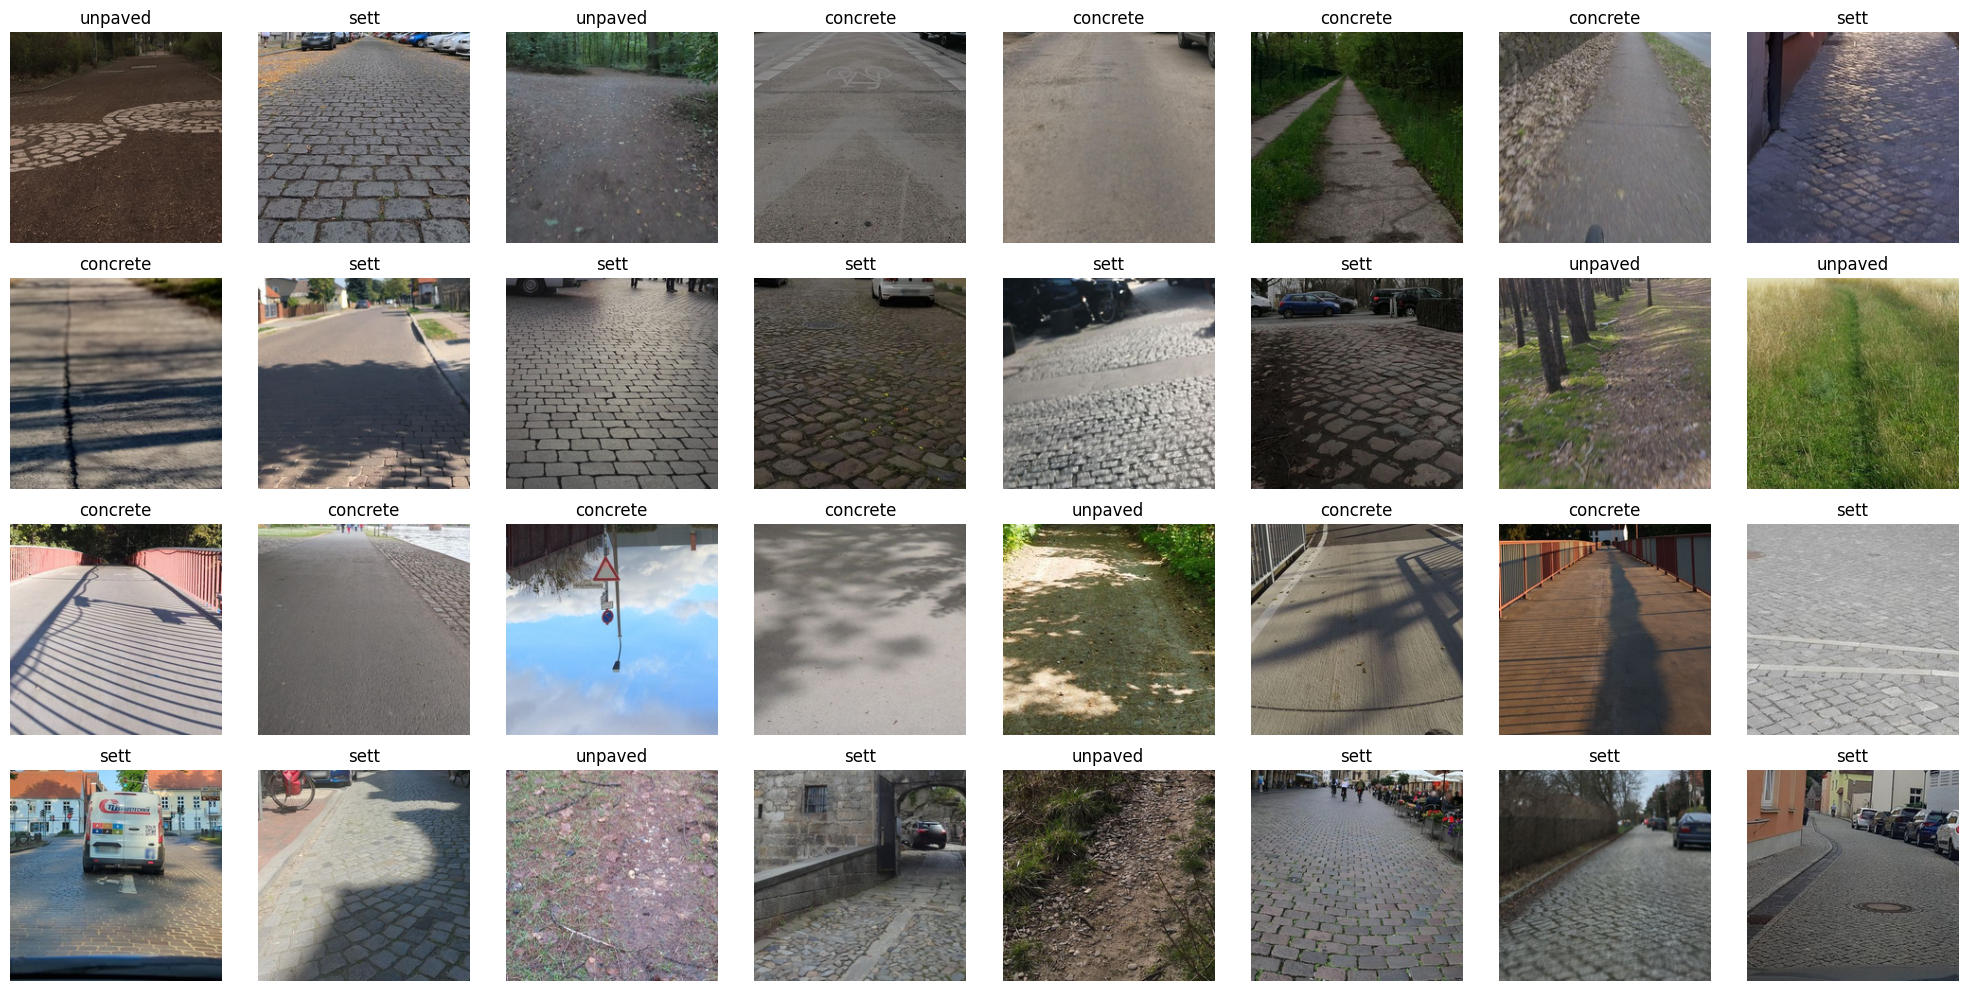

In [49]:
import matplotlib.pyplot as plt

CLASS_NAMES = ("unpaved", "concrete", "sett")

fig, axes = plt.subplots(4, 8, figsize=(20, 10))

for index, ax in enumerate(axes.flat):
    image = images[index].permute(1, 2, 0) #Change dimension to (height, width, channel)

    ax.imshow(image.numpy())
    ax.set_title(CLASS_NAMES[labels[index].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Custom small CNN architecture for image classification

In [50]:
from torch import nn

class SmallCustomCNN(nn.Module):

    def __init__(self, num_classes=3):
        #Init nn.Module
        super().__init__()

        self.features = nn.Sequential(
            #First Conv2D layer input: 3 images channels, output: 32 feature maps
            nn.Conv2d(3, 32, kernel_size=3, padding=1), #Add padding to preserve size
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            #Second Conv2D layer input: 32 feature maps from previous Conv2D layer, output: 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            #Third Conv2D layer input: 64 feature maps from previous Conv2D layer, output: 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        #Pool Convolutional layer from 128x28x28 to 128x2x2
        self.pool = nn.AdaptiveAvgPool2d((2,2))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(512, num_classes), #128*2*2 = 512
        )

    def forward(self, images):
        features = self.features(images)
        pooled = self.pool(features)
        logits = self.classifier(pooled)

        return logits

## Evaluate the model (before training) on 1 batch

In [51]:
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_custom = SmallCustomCNN(num_classes=3).to(device)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

model_custom.eval()

with torch.no_grad():
    logits = model_custom(images)

print("Device:", device)
print("Input:", images.shape)
print("Output:", logits.shape)
print("First image logits:", logits[0])

criterion = nn.CrossEntropyLoss()

loss = criterion(logits, labels)

print("Loss:", loss.item())

Device: cuda
Input: torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 3])
First image logits: tensor([-0.0274,  0.0286,  0.0089], device='cuda:0')
Loss: 1.0962135791778564


## Train on first batch


In [52]:
from torch import nn

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_custom.parameters(), lr=1e-3)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)
#Turn on train mode
model_custom.train()

optimizer.zero_grad()
logits = model_custom(images) #Predict using current weights
loss = criterion(logits, labels) #Calculate current errors

loss.backward() #Calculate gradients
optimizer.step() #Update weights

predictions = logits.detach().argmax(dim=1) #Choose largest class logit as the prediction
accuracy = (predictions == labels).float().mean().item()

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print(f"Batch accuracy: {accuracy:.2%}")

Logits shape: torch.Size([32, 3])
Loss: 1.1006996631622314
Batch accuracy: 31.25%


## Train function and validation function

In [53]:
def train_on_k_epochs(model, loader, criterion, optimizer, device, k_epoch=1):
    if k_epoch < 1:
        raise ValueError("k_epoch must be at least 1.")

    history = []

    for epoch in range(k_epoch):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            predictions = logits.detach().argmax(dim=1)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

        if total_samples == 0:
            raise ValueError("Training loader yielded no samples.")

        epoch_loss = total_loss / total_samples
        epoch_accuracy = total_correct / total_samples
        history.append({
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_accuracy,
        })

    return history


In [54]:
from sklearn.metrics import f1_score


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())

    if total_samples == 0:
        raise ValueError("Evaluation loader yielded no samples.")

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

## Reusable classification metrics

In [55]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


def calculate_metrics(true_labels, predicted_labels, class_names):
    if len(true_labels) == 0:
        raise ValueError("No samples to evaluate.")
    if len(true_labels) != len(predicted_labels):
        raise ValueError("Labels and predictions must have equal lengths.")

    class_ids = list(range(len(class_names)))
    if not set(true_labels).issubset(class_ids):
        raise ValueError("Unknown true class ID.")
    if not set(predicted_labels).issubset(class_ids):
        raise ValueError("Unknown predicted class ID.")

    precision, recall, f1, support = precision_recall_fscore_support(
        true_labels, predicted_labels,
        labels=class_ids, average=None, zero_division=0,
    )
    return {
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "macro_f1": float(f1.mean()),
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "per_class": {
            name: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i]),
            }
            for i, name in enumerate(class_names)
        },
    }


def evaluate_classifier(model, loader, device, class_names):
    model.eval()
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            predictions = logits.argmax(dim=1)
            true_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(predictions.cpu().tolist())

    metrics = calculate_metrics(true_labels, predicted_labels, class_names)
    return metrics, true_labels, predicted_labels


## Export confusion matrix as PNG

Rows are predicted classes; columns are true classes. normalize=True divides each column by its true-class support and displays percentages. Classes with zero support have zero columns.

In [56]:
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def save_confusion_matrix_png(
    true_labels,
    predicted_labels,
    class_names,
    output_path,
    title="Confusion matrix",
    show=True,
    normalize=False,
):
    if len(true_labels) == 0:
        raise ValueError("No samples to plot.")
    if len(true_labels) != len(predicted_labels):
        raise ValueError("Labels and predictions must have equal lengths.")
    if not class_names:
        raise ValueError("class_names must not be empty.")

    class_ids = list(range(len(class_names)))
    if not set(true_labels).issubset(class_ids):
        raise ValueError("Unknown true class ID.")
    if not set(predicted_labels).issubset(class_ids):
        raise ValueError("Unknown predicted class ID.")

    output_path = Path(output_path)
    if output_path.suffix.lower() != ".png":
        raise ValueError("output_path must end with .png.")
    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Normalize by true-class support before transposing.
    # Rows represent predictions; columns represent true classes.
    cm = confusion_matrix(
        true_labels, predicted_labels, labels=class_ids,
        normalize="true" if normalize else None,
    ).T

    fig, ax = plt.subplots(figsize=(7, 6))
    try:
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=ax, cmap="Blues",
            values_format=".1%" if normalize else "d",
            colorbar=False, im_kw={"vmin": 0, "vmax": 1} if normalize else None,
        )
        ax.set_xlabel("Ground truth")
        ax.set_ylabel("Predicted")
        ax.set_title(f"{title} (normalized by true class)" if normalize else title)
        fig.tight_layout()
        fig.savefig(output_path, format="png", dpi=200, bbox_inches="tight")
        if show:
            plt.show()
    finally:
        plt.close(fig)

    return cm


## Train the model

In [57]:
torch.manual_seed(42)

model_custom = SmallCustomCNN(num_classes=3).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_custom.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3,
)

In [58]:
NUM_EPOCHS = 60
PATIENCE = 8

checkpoint_path = Path("/kaggle/working/best_small_cnn.pt")

history = []
best_macro_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = train_on_k_epochs(
        model=model_custom,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        k_epoch=1,
    )[0]

    val_metrics = evaluate(
        model=model_custom,
        loader=val_loader,
        criterion=criterion,
        device=device,
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_metrics["train_loss"],
        "train_accuracy": train_metrics["train_accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })
    old_lr = optimizer.param_groups[0]["lr"]

    scheduler.step(val_metrics["loss"])

    new_lr = optimizer.param_groups[0]["lr"]

    if old_lr != new_lr:
        print(f"Learning rate reduced from {old_lr:.6f} to {new_lr:.6f}.")
    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | "
        f"Train loss: {train_metrics['train_loss']:.4f} | "
        f"Train accuracy: {train_metrics['train_accuracy']:.2%} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2%} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model_custom.state_dict(),
            "epoch": epoch,
            "val_macro_f1": best_macro_f1,
            "class_names": list(CLASS_NAMES),
        }, checkpoint_path)

        print("Saved best checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break
    

Epoch 1/60 | Train loss: 1.0119 | Train accuracy: 48.48% | Val loss: 0.9682 | Val accuracy: 54.04% | Val Macro-F1: 0.5382
Saved best checkpoint.
Epoch 2/60 | Train loss: 0.8624 | Train accuracy: 60.26% | Val loss: 0.7951 | Val accuracy: 65.68% | Val Macro-F1: 0.6278
Saved best checkpoint.
Epoch 3/60 | Train loss: 0.7565 | Train accuracy: 66.63% | Val loss: 0.7836 | Val accuracy: 65.68% | Val Macro-F1: 0.6180
Epoch 4/60 | Train loss: 0.6852 | Train accuracy: 70.78% | Val loss: 0.6921 | Val accuracy: 70.65% | Val Macro-F1: 0.6822
Saved best checkpoint.
Epoch 5/60 | Train loss: 0.6344 | Train accuracy: 73.39% | Val loss: 0.6251 | Val accuracy: 74.38% | Val Macro-F1: 0.7306
Saved best checkpoint.
Epoch 6/60 | Train loss: 0.5964 | Train accuracy: 74.71% | Val loss: 0.6362 | Val accuracy: 73.29% | Val Macro-F1: 0.7239
Epoch 7/60 | Train loss: 0.5629 | Train accuracy: 76.46% | Val loss: 0.5959 | Val accuracy: 75.62% | Val Macro-F1: 0.7449
Saved best checkpoint.
Epoch 8/60 | Train loss: 0.5343

## Validation set evaluation

In [63]:
val_metrics, val_labels, val_predictions = evaluate_classifier(
    model=model_custom,
    loader=val_loader,
    device=device,
    class_names=CLASS_NAMES,
)

print(f"Val accuracy: {val_metrics['accuracy']:.2%}")
print(f"Val Macro-F1: {val_metrics['macro_f1']:.4f}")
print(f"Val macro precision: {val_metrics['macro_precision']:.4f}")
print(f"Val macro recall: {val_metrics['macro_recall']:.4f}")

for class_name, scores in val_metrics["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

Val accuracy: 88.82%
Val Macro-F1: 0.8853
Val macro precision: 0.8852
Val macro recall: 0.8887
unpaved: Precision=0.8907 | Recall=0.8763 | F1=0.8835 | Support=186
concrete: Precision=0.8018 | Recall=0.9062 | F1=0.8509 | Support=192
sett: Precision=0.9631 | Recall=0.8835 | F1=0.9216 | Support=266


## Final test evaluation

Run after selecting the configuration and checkpoint using validation.

In [64]:
import json

# Run the final test evaluation after fixing the experiment configuration.
test_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="test",
    transform=tensor_transform,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=True,
)
if checkpoint["class_names"] != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model_custom.load_state_dict(checkpoint["model_state_dict"])
model_custom.to(device)

test_metrics, test_labels, test_predictions = evaluate_classifier(
    model=model_custom,
    loader=test_loader,
    device=device,
    class_names=CLASS_NAMES,
)

print("Test samples:", len(test_labels))
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Test accuracy: {test_metrics['accuracy']:.2%}")
print(f"Test Macro-F1: {test_metrics['macro_f1']:.4f}")
print(f"Test macro precision: {test_metrics['macro_precision']:.4f}")
print(f"Test macro recall: {test_metrics['macro_recall']:.4f}")
for class_name, scores in test_metrics["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

output_dir = Path("/kaggle/working")
with (output_dir / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump({
        "checkpoint_epoch": checkpoint["epoch"],
        "class_names": list(CLASS_NAMES),
        **test_metrics,
    }, file, indent=2)

# shuffle=False and drop_last=False preserve the dataset row order.
with (output_dir / "test_predictions.csv").open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.writer(file)
    writer.writerow(["image_id", "true_class_id", "predicted_class_id"])
    for row, true_id, predicted_id in zip(
        test_dataset.rows, test_labels, test_predictions
    ):
        writer.writerow([row["image_id"], true_id, predicted_id])


Test samples: 133
Checkpoint epoch: 35
Test accuracy: 87.97%
Test Macro-F1: 0.8384
Test macro precision: 0.8191
Test macro recall: 0.8710
unpaved: Precision=0.9500 | Recall=0.8941 | F1=0.9212 | Support=85
concrete: Precision=0.6364 | Recall=0.8750 | F1=0.7368 | Support=16
sett: Precision=0.8710 | Recall=0.8438 | F1=0.8571 | Support=32


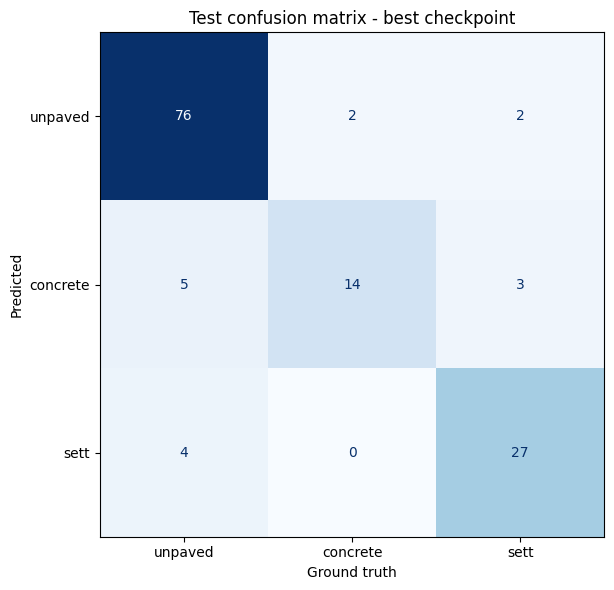

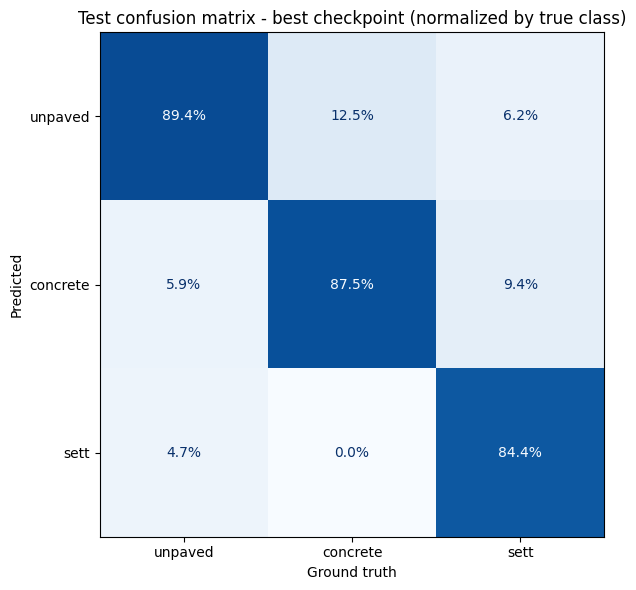

In [65]:
test_cm = save_confusion_matrix_png(
    true_labels=test_labels,
    predicted_labels=test_predictions,
    class_names=CLASS_NAMES,
    output_path="/kaggle/working/test_confusion_matrix.png",
    title="Test confusion matrix - best checkpoint",
)

# Save the normalized version as a separate PNG.
test_cm_normalized = save_confusion_matrix_png(
    true_labels=test_labels,
    predicted_labels=test_predictions,
    class_names=CLASS_NAMES,
    output_path="/kaggle/working/test_confusion_matrix_normalized.png",
    title="Test confusion matrix - best checkpoint",
    normalize=True,
)


# Fine-tuning pretrained model
Fine-tune MobileNetV2 and ResNet50 model trained on ImageNet-1k 

# MobileNetV2 Fine-tuning

## Import the model and define the modified model class 


In [66]:
from torchvision.models  import MobileNet_V2_Weights, mobilenet_v2

model_mobilenetv2 = mobilenet_v2(pretrained=True)


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [67]:
from torch import nn

class ModifiedMobileNetV2(nn.Module):
    def __init__(self, num_classes=3, model_mobilenetv2=None):
        super().__init__()
        self.backbone = model_mobilenetv2.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(1280, num_classes),
        )

    def forward(self, images):
        features = self.backbone(images)
        pooled = self.pool(features)
        logits = self.classifier(pooled)
        return logits



## Declare the modified MobileNetV2 version and freeze the backbone

In [68]:
model_mobilenetv2_modified = ModifiedMobileNetV2(num_classes=3, model_mobilenetv2=model_mobilenetv2).to(device)


for param in model_mobilenetv2_modified.backbone.parameters():
    param.requires_grad = False

criterion = nn.CrossEntropyLoss()

optimizer_mobilenetv2 = torch.optim.Adam(model_mobilenetv2_modified.parameters(), lr=1e-3)

scheduler_mobilenetv2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mobilenetv2, mode="min", factor=0.5, patience=3
)


In [69]:
NUM_EPOCHS_MOBILENETV2 = 60
PATIENCE_MOBILENETV2 = 8

checkpoint_path_mobilenetv2 = Path("/kaggle/working/best_mobilenetv2.pt")

history_mobilenetv2 = []
best_macro_f1_mobilenetv2 = -1.0
epochs_without_improvement_mobilenetv2 = 0

for epoch in range(1, NUM_EPOCHS_MOBILENETV2 + 1):
    train_metrics_mobilenetv2 = train_on_k_epochs(
        model=model_mobilenetv2_modified,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer_mobilenetv2,
        device=device,
        k_epoch=1,
    )[0]

    val_metrics_mobilenetv2 = evaluate(
        model=model_mobilenetv2_modified,
        loader=val_loader,
        criterion=criterion,
        device=device,
    )

    history_mobilenetv2.append({
        "epoch": epoch,
        "train_loss": train_metrics_mobilenetv2["train_loss"],
        "train_accuracy": train_metrics_mobilenetv2["train_accuracy"],
        "val_loss": val_metrics_mobilenetv2["loss"],
        "val_accuracy": val_metrics_mobilenetv2["accuracy"],
        "val_macro_f1": val_metrics_mobilenetv2["macro_f1"],
    })
    old_lr = optimizer_mobilenetv2.param_groups[0]["lr"]

    scheduler_mobilenetv2.step(val_metrics_mobilenetv2["loss"])

    new_lr = optimizer_mobilenetv2.param_groups[0]["lr"]

    if old_lr != new_lr:
        print(f"Learning rate reduced from {old_lr:.6f} to {new_lr:.6f}.")
        
    print(
        f"Epoch {epoch}/{NUM_EPOCHS_MOBILENETV2} | "
        f"Train loss: {train_metrics_mobilenetv2['train_loss']:.4f} | "
        f"Train accuracy: {train_metrics_mobilenetv2['train_accuracy']:.2%} | "
        f"Val loss: {val_metrics_mobilenetv2['loss']:.4f} | "
        f"Val accuracy: {val_metrics_mobilenetv2['accuracy']:.2%} | "
        f"Val Macro-F1: {val_metrics_mobilenetv2['macro_f1']:.4f}"
    )

    if val_metrics_mobilenetv2["macro_f1"] > best_macro_f1_mobilenetv2:
        best_macro_f1_mobilenetv2 = val_metrics_mobilenetv2["macro_f1"]
        epochs_without_improvement_mobilenetv2 = 0

        torch.save({
            "model_state_dict": model_mobilenetv2_modified.state_dict(),
            "epoch": epoch,
            "val_macro_f1": best_macro_f1_mobilenetv2,
            "class_names": list(CLASS_NAMES),
        }, checkpoint_path_mobilenetv2)

        print("Saved best checkpoint for MobileNetV2.")

Epoch 1/60 | Train loss: 0.4959 | Train accuracy: 81.93% | Val loss: 0.2859 | Val accuracy: 89.91% | Val Macro-F1: 0.8933
Saved best checkpoint for MobileNetV2.
Epoch 2/60 | Train loss: 0.2991 | Train accuracy: 89.43% | Val loss: 0.2478 | Val accuracy: 91.77% | Val Macro-F1: 0.9130
Saved best checkpoint for MobileNetV2.
Epoch 3/60 | Train loss: 0.2718 | Train accuracy: 90.09% | Val loss: 0.2357 | Val accuracy: 92.08% | Val Macro-F1: 0.9165
Saved best checkpoint for MobileNetV2.
Epoch 4/60 | Train loss: 0.2568 | Train accuracy: 90.68% | Val loss: 0.2455 | Val accuracy: 90.99% | Val Macro-F1: 0.9050
Epoch 5/60 | Train loss: 0.2459 | Train accuracy: 91.14% | Val loss: 0.1954 | Val accuracy: 92.39% | Val Macro-F1: 0.9200
Saved best checkpoint for MobileNetV2.
Epoch 6/60 | Train loss: 0.2251 | Train accuracy: 91.49% | Val loss: 0.2002 | Val accuracy: 92.70% | Val Macro-F1: 0.9237
Saved best checkpoint for MobileNetV2.
Epoch 7/60 | Train loss: 0.2204 | Train accuracy: 92.27% | Val loss: 0.22

## Evaluate fine-tuned model on validation set

In [70]:
val_metrics_mobilenetv2, val_labels_mobilenetv2, val_predictions_mobilenetv2 = evaluate_classifier(
    model=model_mobilenetv2_modified,
    loader=val_loader,
    device=device,
    class_names=CLASS_NAMES,
)

print(f"Val accuracy (MobileNetV2): {val_metrics_mobilenetv2['accuracy']:.2%}")
print(f"Val Macro-F1 (MobileNetV2): {val_metrics_mobilenetv2['macro_f1']:.4f}")
print(f"Val macro precision (MobileNetV2): {val_metrics_mobilenetv2['macro_precision']:.4f}")
print(f"Val macro recall (MobileNetV2): {val_metrics_mobilenetv2['macro_recall']:.4f}")

for class_name, scores in val_metrics_mobilenetv2["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

Val accuracy (MobileNetV2): 93.32%
Val Macro-F1 (MobileNetV2): 0.9300
Val macro precision (MobileNetV2): 0.9282
Val macro recall (MobileNetV2): 0.9331
unpaved: Precision=0.8856 | Recall=0.9570 | F1=0.9199 | Support=186
concrete: Precision=0.9110 | Recall=0.9062 | F1=0.9086 | Support=192
sett: Precision=0.9881 | Recall=0.9361 | F1=0.9614 | Support=266


## Final test on the test set 

In [71]:
test_dataset_mobilenetv2 = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="test",
    transform=tensor_transform,
)

test_loader_mobilenetv2 = DataLoader(
    test_dataset_mobilenetv2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

checkpoint_mobilenetv2 = torch.load(
    checkpoint_path_mobilenetv2, map_location=device, weights_only=True,    
)

if checkpoint_mobilenetv2["class_names"] != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model_mobilenetv2_modified.load_state_dict(checkpoint_mobilenetv2["model_state_dict"])
model_mobilenetv2_modified.to(device)

test_metrics_mobilenetv2, test_labels_mobilenetv2, test_predictions_mobilenetv2 = evaluate_classifier(
    model=model_mobilenetv2_modified,
    loader=test_loader_mobilenetv2,
    device=device,
    class_names=CLASS_NAMES,
)

print("Test samples (MobileNetV2):", len(test_labels_mobilenetv2))
print("Checkpoint epoch (MobileNetV2):", checkpoint_mobilenetv2["epoch"])
print(f"Test accuracy (MobileNetV2): {test_metrics_mobilenetv2['accuracy']:.2%}")
print(f"Test Macro-F1 (MobileNetV2): {test_metrics_mobilenetv2['macro_f1']:.4f}")
print(f"Test macro precision (MobileNetV2): {test_metrics_mobilenetv2['macro_precision']:.4f}")
print(f"Test macro recall (MobileNetV2): {test_metrics_mobilenetv2['macro_recall']:.4f}")

for class_name, scores in test_metrics_mobilenetv2["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

output_dir_mobilenetv2 = Path("/kaggle/working")
with (output_dir_mobilenetv2 / "test_metrics_mobilenetv2.json").open("w", encoding="utf-8") as file:
    json.dump({
        "checkpoint_epoch": checkpoint_mobilenetv2["epoch"],
        "class_names": list(CLASS_NAMES),
        **test_metrics_mobilenetv2,
    }, file, indent=2)

with (output_dir_mobilenetv2 / "test_predictions_mobilenetv2.csv").open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.writer(file)
    writer.writerow(["image_id", "true_class_id", "predicted_class_id"])
    for row, true_id, predicted_id in zip(
        test_dataset_mobilenetv2.rows, test_labels_mobilenetv2, test_predictions_mobilenetv2
    ):
        writer.writerow([row["image_id"], true_id, predicted_id])

Test samples (MobileNetV2): 133
Checkpoint epoch (MobileNetV2): 53
Test accuracy (MobileNetV2): 90.98%
Test Macro-F1 (MobileNetV2): 0.8791
Test macro precision (MobileNetV2): 0.8560
Test macro recall (MobileNetV2): 0.9126
unpaved: Precision=0.9620 | Recall=0.8941 | F1=0.9268 | Support=85
concrete: Precision=0.6667 | Recall=0.8750 | F1=0.7568 | Support=16
sett: Precision=0.9394 | Recall=0.9688 | F1=0.9538 | Support=32


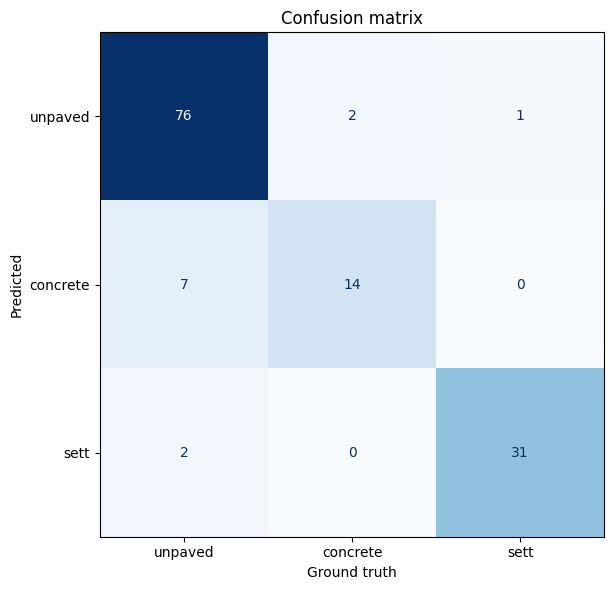

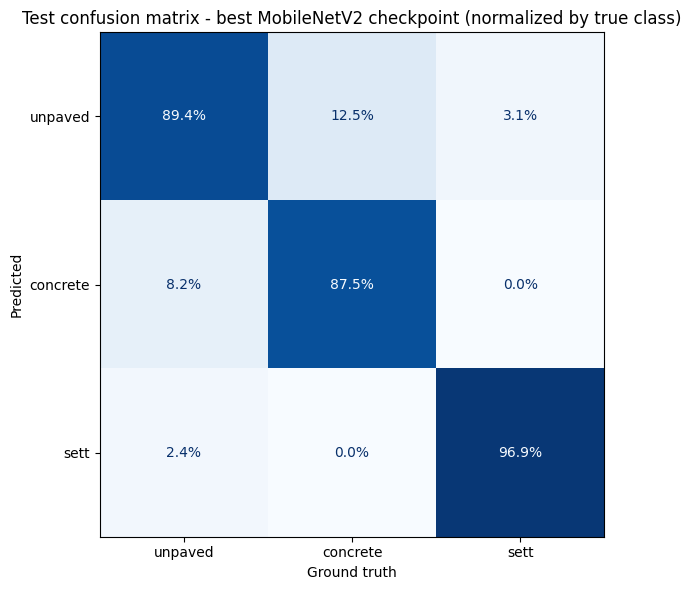

In [72]:
test_cm_mobilenetv2 = save_confusion_matrix_png(
    true_labels=test_labels_mobilenetv2,
    predicted_labels=test_predictions_mobilenetv2,
    class_names=CLASS_NAMES,
    output_path=output_dir_mobilenetv2 / "test_confusion_matrix_mobilenetv2.png"
)

test_cm_normalized_mobilenetv2 = save_confusion_matrix_png(
    true_labels=test_labels_mobilenetv2,
    predicted_labels=test_predictions_mobilenetv2,
    class_names=CLASS_NAMES,
    output_path=output_dir_mobilenetv2 / "test_confusion_matrix_normalized_mobilenetv2.png",
    title="Test confusion matrix - best MobileNetV2 checkpoint",
    normalize=True,
)
